# Proyek Analisis Data: Kualitas Udara Stasiun Dongsi, Beijing (PRSA)

- **Nama:** [Input Nama]
- **Email:** [Input Email]
- **ID Dicoding:** [Input Username]

**Dataset:** *Beijing Multi-Site Air-Quality Data* (PRSA), stasiun **Dongsi**, data per jam, 1 Maret 2013 – 28 Februari 2017.

## Menentukan Pertanyaan Bisnis

Konteks: pemerintah kota atau dinas lingkungan hidup perlu mengetahui **kapan** dan **dalam kondisi cuaca apa** polusi PM2.5 paling parah, agar peringatan dini dan pembatasan emisi dapat dijadwalkan tepat sasaran.

- **Pertanyaan 1:** Selama periode Maret 2013 – Februari 2017, pada bulan dan jam berapa rata-rata PM2.5 di stasiun Dongsi paling tinggi, dan berapa persen hari yang masuk tiap kategori kualitas udara di setiap periode Maret–Februari?
- **Pertanyaan 2:** Selama periode Maret 2013 – Februari 2017, bagaimana perbedaan rata-rata PM2.5 menurut kecepatan angin dan arah angin, dan kombinasi mana yang menghasilkan PM2.5 tertinggi?

**Penerapan elemen SMART pada kedua pertanyaan:**

| Elemen SMART | Pertanyaan 1 | Pertanyaan 2 |
|---|---|---|
| Specific | PM2.5 di satu stasiun (Dongsi); dimensi bulan, jam, kategori harian | PM2.5 terhadap kecepatan dan arah angin |
| Measurable | Rata-rata µg/m³, % hari per kategori | Rata-rata µg/m³, % jam di atas 75 µg/m³ per kombinasi |
| Action-oriented | Menjadwalkan advisori dan pembatasan emisi musiman | Memicu peringatan dini saat angin lemah dan arah dari sektor tertentu |
| Relevant | Tujuan utama: menekan paparan PM2.5 | Sama |
| Time-bound | 1 Mar 2013 – 28 Feb 2017 (4 periode penuh Maret–Februari) | Sama |

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", rc={"axes.grid.axis": "y"})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## Data Wrangling

### Gathering Data

#### Load df data PRSA stasiun Dongsi

Data dimuat dari berkas CSV asli (satu stasiun, data per jam).

In [2]:
from pathlib import Path

NAMA_FILE = "PRSA_Data_Dongsi_20130301-20170228.csv"

# Cari berkas data di beberapa lokasi umum agar notebook tetap jalan
# walau dibuka dari folder lain (VS Code, Jupyter, Colab).
kandidat = [
    Path("data") / NAMA_FILE,              # dijalankan dari folder submission
    Path(NAMA_FILE),                       # CSV satu folder dengan notebook
    Path("..") / "data" / NAMA_FILE,       # notebook dipindah ke subfolder
    Path("submission/data") / NAMA_FILE,   # dijalankan dari folder induk
    Path("/content") / NAMA_FILE,          # Google Colab (upload manual)
    Path("/content/data") / NAMA_FILE,
]
DATA_PATH = next((p for p in kandidat if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        f"Berkas '{NAMA_FILE}' tidak ditemukan.\n"
        f"Folder kerja saat ini: {Path.cwd()}\n"
        "Pastikan folder 'data' ikut terekstrak dari zip, atau jalankan Jupyter dari folder 'submission'."
    )

# Folder keluaran: <folder submission>/dashboard
DATA_ABS = DATA_PATH.resolve()
BASE_DIR = DATA_ABS.parent.parent if DATA_ABS.parent.name == "data" else DATA_ABS.parent
OUT_DIR = BASE_DIR / "dashboard"
OUT_DIR.mkdir(exist_ok=True)

print("Membaca data dari:", DATA_PATH.resolve())
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

Membaca data dari: /home/claude/submission/data/PRSA_Data_Dongsi_20130301-20170228.csv


(35064, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,9.00,9.00,3.00,17.00,300.00,89.00,-0.50,"1,024.50",-21.40,0.00,NNW,5.70,Dongsi
1,2,2013,3,1,1,4.00,4.00,3.00,16.00,300.00,88.00,-0.70,"1,025.10",-22.10,0.00,NW,3.90,Dongsi
2,3,2013,3,1,2,7.00,7.00,NaN,17.00,300.00,60.00,-1.20,"1,025.30",-24.60,0.00,NNW,5.30,Dongsi
3,4,2013,3,1,3,3.00,3.00,5.00,18.00,NaN,NaN,-1.40,"1,026.20",-25.50,0.00,N,4.90,Dongsi
4,5,2013,3,1,4,3.00,3.00,7.00,NaN,200.00,84.00,-1.90,"1,027.10",-24.50,0.00,NNW,3.20,Dongsi


**Insight:**
- Terdapat 35.064 baris dan 18 kolom. Kolom waktu terpisah menjadi `year`, `month`, `day`, `hour`.
- Hanya ada satu stasiun (`Dongsi`), jadi analisis geospasial dan RFM **tidak relevan** untuk dataset ini. Teknik lanjutan yang dipakai adalah *manual grouping* dan *binning*.

### Assessing Data

#### Identifying timestamp completeness and duplicate problem

In [3]:
df.info()
print("Baris duplikat penuh      :", df.duplicated().sum())
print("Duplikat kunci waktu      :", df.duplicated(["year", "month", "day", "hour"]).sum())
waktu = pd.to_datetime(df[["year", "month", "day", "hour"]])
jam_seharusnya = int((waktu.max() - waktu.min()).total_seconds() / 3600) + 1
print("Rentang waktu             :", waktu.min(), "s/d", waktu.max())
print("Jumlah jam seharusnya     :", jam_seharusnya, "| jumlah baris:", len(df))

<class 'pandas.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   No       35064 non-null  int64  
 1   year     35064 non-null  int64  
 2   month    35064 non-null  int64  
 3   day      35064 non-null  int64  
 4   hour     35064 non-null  int64  
 5   PM2.5    34314 non-null  float64
 6   PM10     34511 non-null  float64
 7   SO2      34401 non-null  float64
 8   NO2      33463 non-null  float64
 9   CO       31867 non-null  float64
 10  O3       34400 non-null  float64
 11  TEMP     35044 non-null  float64
 12  PRES     35044 non-null  float64
 13  DEWP     35044 non-null  float64
 14  RAIN     35044 non-null  float64
 15  wd       34986 non-null  str    
 16  WSPM     35050 non-null  float64
 17  station  35064 non-null  str    
dtypes: float64(11), int64(5), str(2)
memory usage: 5.1 MB
Baris duplikat penuh      : 0
Duplikat kunci waktu      : 0
Rentang waktu          

#### Identifying missing value problem

In [4]:
mv = pd.DataFrame({"jumlah": df.isna().sum(), "persen": df.isna().mean() * 100})
mv[mv["jumlah"] > 0].sort_values("jumlah", ascending=False)

,jumlah,persen
CO,3197,9.12
NO2,1601,4.57
PM2.5,750,2.14
O3,664,1.89
SO2,663,1.89
PM10,553,1.58
wd,78,0.22
TEMP,20,0.06
PRES,20,0.06
DEWP,20,0.06


In [5]:
# Panjang celah (jam berturut-turut) missing terpanjang per kolom
def celah_terpanjang(s):
    m = s.isna()
    grup = (m != m.shift()).cumsum()
    return int(m.groupby(grup).sum().max())

for kol in ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]:
    print(f"{kol:6s} celah terpanjang: {celah_terpanjang(df[kol]):5d} jam")

PM2.5  celah terpanjang:    58 jam
PM10   celah terpanjang:    57 jam
SO2    celah terpanjang:    57 jam
NO2    celah terpanjang:   900 jam
CO     celah terpanjang:  1517 jam
O3     celah terpanjang:    57 jam


#### Identifying inconsistent value problem (PM2.5 > PM10)

PM2.5 adalah bagian dari PM10, sehingga PM2.5 > PM10 secara fisik janggal (kecuali galat instrumen).

In [6]:
mask = df["PM2.5"] > df["PM10"]
selisih = (df.loc[mask, "PM2.5"] - df.loc[mask, "PM10"])
print("Baris PM2.5 > PM10 :", mask.sum(), f"({mask.mean()*100:.1f}%)")
print(selisih.describe())

Baris PM2.5 > PM10 : 2156 (6.1%)
count   2,156.00
mean       27.43
std        27.71
min         1.00
25%         8.00
50%        20.00
75%        38.00
max       270.00
dtype: float64


#### Identifying outlier problem

In [7]:
print("PM2.5 > 500 µg/m³  :", (df["PM2.5"] > 500).sum(), "baris")
print("CO == 10000        :", (df["CO"] == 10000).sum(), "baris (kemungkinan batas atas sensor)")
print("RAIN > 20 mm       :", (df["RAIN"] > 20).sum(), "baris")
print("WSPM max           :", df["WSPM"].max(), "m/s")
df[["PM2.5", "PM10", "WSPM", "TEMP"]].describe()

PM2.5 > 500 µg/m³  : 112 baris
CO == 10000        : 10 baris (kemungkinan batas atas sensor)
RAIN > 20 mm       : 13 baris
WSPM max           : 10.5 m/s


,PM2.5,PM10,WSPM,TEMP
count,"34,314.00","34,511.00","35,050.00","35,044.00"
mean,86.19,110.34,1.86,13.67
std,86.58,98.22,1.28,11.46
min,3.00,2.00,0.00,-16.80
25%,22.00,38.00,1.00,3.10
50%,61.00,86.00,1.50,14.60
75%,119.00,151.00,2.40,23.50
max,737.00,955.00,10.50,41.10


#### Identifying inconsistent precision problem (SO2 dan O3)

In [8]:
for kol in ["SO2", "O3", "NO2", "PM2.5"]:
    v = df[kol].dropna()
    print(f"{kol:6s} nilai non-integer: {(v % 1 != 0).sum():5d} dari {len(v)}")

SO2    nilai non-integer:  1421 dari 34401
O3     nilai non-integer:   996 dari 34400
NO2    nilai non-integer:  1511 dari 33463
PM2.5  nilai non-integer:    17 dari 34314


#### Identifying incomplete period problem

Karena data mulai Maret 2013 dan berakhir Februari 2017, tahun kalender 2013 dan 2017 tidak lengkap.

In [9]:
df.groupby("year")["month"].agg(bulan_awal="min", bulan_akhir="max", jumlah_jam="size")

,bulan_awal,bulan_akhir,jumlah_jam
year,,,
2013,3,12,7344
2014,1,12,8760
2015,1,12,8760
2016,1,12,8784
2017,1,2,1416


**Steps to Take:**
- **Missing value:** CO (±9,1%), NO2 (±4,6%), PM2.5 (±2,1%), dan `wd` (78 baris) memiliki nilai kosong. Celah CO sangat panjang (hingga 1.517 jam). PM2.5 diinterpolasi waktu **hanya untuk celah pendek (≤ 6 jam)**, dengan penanda `pm25_terukur` dicatat sebelum interpolasi agar validitas harian dihitung dari jam yang benar-benar terukur. CO dan NO2 **tidak** diisi dan tidak dipakai pada analisis utama. Baris `wd` kosong dikeluarkan hanya pada analisis arah angin.
- **Nilai tidak konsisten (PM2.5 > PM10):** terjadi pada ±6% baris. Baris diberi penanda `pm25_gt_pm10` dan **tidak dihapus**, kemudian dilakukan uji sensitivitas.
- **Outlier:** PM2.5 > 500 µg/m³ pada 112 baris **dipertahankan** karena kemungkinan besar merupakan episode polusi nyata; penghapusan akan membiaskan hasil ke bawah.
- **Presisi tidak seragam:** SO2 (1.421 nilai) dan O3 (996 nilai) memiliki nilai non-integer padahal mayoritas nilainya bulat. Kondisi ini didokumentasikan, dan kedua variabel tidak dipakai pada analisis utama.
- **Periode tidak lengkap:** tahun kalender 2013 dan 2017 hanya parsial. Dibuat kolom `periode` (Maret–Februari) agar keempat periode dapat dibandingkan.

**Insight:**
- Kolom yang dipakai pada analisis utama (PM2.5, WSPM, `wd`, dan waktu) relatif lengkap. PM2.5 hanya kehilangan ±2,1% nilai, sedangkan CO dan NO2 memiliki celah panjang sehingga tidak digunakan.
- Inkonsistensi PM2.5 > PM10 (±6% baris) dan outlier PM2.5 > 500 µg/m³ (112 baris) diperlakukan berbeda: yang pertama diberi penanda dan diuji sensitivitasnya, yang kedua dipertahankan sebagai kejadian nyata.
- Data per jam mencakup 1 Mar 2013 – 28 Feb 2017 tanpa timestamp yang hilang, sehingga keempat periode Maret–Februari dapat dibandingkan secara langsung.

### Cleaning Data

#### Fixing missing value and inconsistent value problem

In [10]:
dc = df.copy()
dc["datetime"] = pd.to_datetime(dc[["year", "month", "day", "hour"]])
dc = dc.sort_values("datetime").reset_index(drop=True)

# 1) Penanda inkonsistensi PM2.5 vs PM10 (tidak dihapus)
dc["pm25_gt_pm10"] = (dc["PM2.5"] > dc["PM10"]).astype(int)

# 2) Penanda jam yang benar-benar terukur (dicatat sebelum interpolasi)
dc["pm25_terukur"] = dc["PM2.5"].notna().astype(int)

# 3) Interpolasi PM2.5 hanya untuk celah pendek (<= 6 jam)
sebelum = dc["PM2.5"].isna().sum()
dc["PM2.5"] = (dc.set_index("datetime")["PM2.5"]
                 .interpolate(method="time", limit=6, limit_area="inside")
                 .to_numpy())
print(f"Missing PM2.5: {sebelum} -> {dc['PM2.5'].isna().sum()}")

# 4) Buang kolom konstan / indeks
dc = dc.drop(columns=["No", "station"])

Missing PM2.5: 750 -> 324


#### Fixing incomplete period problem and creating derived features

Fitur turunan dibuat dengan *manual grouping* dan *binning*; aturan ditetapkan di awal, bukan dari hasil data.

In [11]:
# Musim meteorologis (Belahan Bumi Utara)
musim_map = {12: "Dingin", 1: "Dingin", 2: "Dingin", 3: "Semi", 4: "Semi", 5: "Semi",
             6: "Panas", 7: "Panas", 8: "Panas", 9: "Gugur", 10: "Gugur", 11: "Gugur"}
dc["musim"] = dc["month"].map(musim_map)

# Periode Maret-Februari
th = np.where(dc["month"] >= 3, dc["year"], dc["year"] - 1)
dc["periode"] = [f"Mar {t}-Feb {t+1}" for t in th]

# Binning kecepatan angin (m/s)
bin_angin = [-0.01, 1, 2, 3, 5, np.inf]
lab_angin = ["≤1 (sangat lemah)", "1-2 (lemah)", "2-3 (sedang)", "3-5 (cukup kuat)", ">5 (kuat)"]
dc["kelas_angin"] = pd.cut(dc["WSPM"], bins=bin_angin, labels=lab_angin)

# Manual grouping arah angin -> kuadran (derajat kompas, batas kiri-tertutup)
derajat = {"N": 0, "NNE": 22.5, "NE": 45, "ENE": 67.5, "E": 90, "ESE": 112.5, "SE": 135, "SSE": 157.5,
           "S": 180, "SSW": 202.5, "SW": 225, "WSW": 247.5, "W": 270, "WNW": 292.5, "NW": 315, "NNW": 337.5}
dc["kuadran"] = pd.cut(dc["wd"].map(derajat), bins=[0, 90, 180, 270, 360],
                       labels=["Utara-Timur Laut", "Timur-Tenggara", "Selatan-Barat Daya", "Barat-Barat Laut"],
                       right=False, include_lowest=True)

# Blok waktu
dc["blok_waktu"] = pd.cut(dc["hour"], bins=[-1, 5, 11, 17, 23],
                          labels=["Dini hari (0-5)", "Pagi (6-11)", "Siang-sore (12-17)", "Malam (18-23)"])
dc["tanggal"] = dc["datetime"].dt.normalize()
dc[["datetime", "PM2.5", "WSPM", "wd", "musim", "periode", "kelas_angin", "kuadran", "blok_waktu"]].head()

,datetime,PM2.5,WSPM,wd,musim,periode,kelas_angin,kuadran,blok_waktu
0,2013-03-01 00:00:00,9.00,5.70,NNW,Semi,Mar 2013-Feb 2014,>5 (kuat),Barat-Barat Laut,Dini hari (0-5)
1,2013-03-01 01:00:00,4.00,3.90,NW,Semi,Mar 2013-Feb 2014,3-5 (cukup kuat),Barat-Barat Laut,Dini hari (0-5)
2,2013-03-01 02:00:00,7.00,5.30,NNW,Semi,Mar 2013-Feb 2014,>5 (kuat),Barat-Barat Laut,Dini hari (0-5)
3,2013-03-01 03:00:00,3.00,4.90,N,Semi,Mar 2013-Feb 2014,3-5 (cukup kuat),Utara-Timur Laut,Dini hari (0-5)
4,2013-03-01 04:00:00,3.00,3.20,NNW,Semi,Mar 2013-Feb 2014,3-5 (cukup kuat),Barat-Barat Laut,Dini hari (0-5)


#### Sensitivity test for inconsistent value problem

Uji sensitivitas dilakukan untuk memeriksa apakah baris dengan PM2.5 > PM10 mengubah kesimpulan.

In [12]:
semua = dc.groupby("month")["PM2.5"].mean()
bersih = dc[dc["pm25_gt_pm10"] == 0].groupby("month")["PM2.5"].mean()
print("3 bulan tertinggi (semua data)  :", semua.nlargest(3).index.tolist())
print("3 bulan tertinggi (tanpa flag)  :", bersih.nlargest(3).index.tolist())
a1 = dc.groupby("kelas_angin", observed=True)["PM2.5"].mean()
a2 = dc[dc["pm25_gt_pm10"] == 0].groupby("kelas_angin", observed=True)["PM2.5"].mean()
print("Urutan kelas angin sama?        :", a1.sort_values().index.tolist() == a2.sort_values().index.tolist())

3 bulan tertinggi (semua data)  : [12, 1, 3]
3 bulan tertinggi (tanpa flag)  : [12, 3, 1]
Urutan kelas angin sama?        : True


#### Saving cleaned data

Data bersih disimpan sebagai `main_data.csv` untuk digunakan oleh dashboard.

In [13]:
kolom = ["datetime", "tanggal", "PM2.5", "TEMP", "WSPM", "wd", "month", "hour", "musim", "periode",
         "kelas_angin", "kuadran", "blok_waktu", "pm25_gt_pm10", "pm25_terukur"]
dc[kolom].to_csv(OUT_DIR / "main_data.csv", index=False)
print("Tersimpan di:", (OUT_DIR / "main_data.csv").resolve(), f"({os.path.getsize(OUT_DIR / 'main_data.csv') / 1e6:.1f} MB)")

Tersimpan di: /home/claude/submission/dashboard/main_data.csv (4.5 MB)


**Insight:**
- Interpolasi celah ≤ 6 jam menurunkan jumlah PM2.5 kosong dari 750 menjadi 324 jam. Sisanya adalah celah panjang yang sengaja tidak diisi.
- Pengecualian 2.156 baris PM2.5 > PM10 hanya menukar urutan Januari dan Maret; tiga bulan tertinggi tetap Desember, Januari, dan Maret. Pola Oktober–Maret lebih tinggi daripada April–September dan urutan kelas kecepatan angin tidak berubah.
- Fitur `musim`, `periode`, `kelas_angin`, `kuadran`, dan `blok_waktu` dibuat dengan aturan tetap sehingga hasil pengelompokan tidak bergantung pada hasil analisis.

## Exploratory Data Analysis (EDA)

### Explore Pola Waktu PM2.5 (Pertanyaan 1)

> Selama periode Maret 2013 – Februari 2017, pada bulan dan jam berapa rata-rata PM2.5 di stasiun Dongsi paling tinggi, dan berapa persen hari yang masuk tiap kategori kualitas udara di setiap periode Maret–Februari?

In [14]:
nama_bulan = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
bulanan = dc.groupby("month")["PM2.5"].agg(rata2="mean", median="median", n="count")
bulanan.index = nama_bulan
print("Rata-rata keseluruhan:", round(dc["PM2.5"].mean(), 1))
bulanan.round(1)

Rata-rata keseluruhan: 86.1


,rata2,median,n
Jan,100.30,67.00,2976
Feb,94.90,49.00,2709
Mar,100.20,76.00,2972
Apr,77.30,66.00,2880
Mei,69.50,55.00,2961
Jun,73.40,57.00,2791
Jul,80.30,68.00,2863
Agu,58.60,48.00,2940
Sep,67.00,53.00,2867
Okt,98.30,63.00,2936


In [15]:
# Apakah pola bulanan konsisten antar periode? (menguji agar tidak ditentukan satu tahun saja)
pivot_bp = dc.pivot_table(index="month", columns="periode", values="PM2.5", aggfunc="mean")
pivot_bp.index = nama_bulan
print("Bulan tertinggi tiap periode:", pivot_bp.idxmax().to_dict())
pivot_bp.round(1)

Bulan tertinggi tiap periode: {'Mar 2013-Feb 2014': 'Feb', 'Mar 2014-Feb 2015': 'Okt', 'Mar 2015-Feb 2016': 'Des', 'Mar 2016-Feb 2017': 'Des'}


periode,Mar 2013-Feb 2014,Mar 2014-Feb 2015,Mar 2015-Feb 2016,Mar 2016-Feb 2017
Jan,104.10,101.00,69.40,126.90
Feb,154.20,109.00,43.20,75.10
Mar,108.40,99.90,93.30,99.20
Apr,65.30,89.90,77.20,77.00
Mei,91.40,63.70,59.50,63.40
Jun,108.70,57.70,66.40,61.90
Jul,73.40,98.90,69.10,79.40
Agu,64.90,69.50,49.60,51.00
Sep,85.30,67.70,54.40,60.60
Okt,102.60,116.90,80.10,93.50


In [16]:
per_jam = dc.groupby("hour")["PM2.5"].mean()
print("Jam tertinggi:", per_jam.idxmax(), "->", round(per_jam.max(), 1))
print("Jam terendah :", per_jam.idxmin(), "->", round(per_jam.min(), 1))
print("Rasio tertinggi/terendah:", round(per_jam.max() / per_jam.min(), 2))
dc.groupby("blok_waktu", observed=True)["PM2.5"].mean().round(1)

Jam tertinggi: 22 -> 97.6
Jam terendah : 16 -> 77.9
Rasio tertinggi/terendah: 1.25


blok_waktu
Dini hari (0-5)      92.80
Pagi (6-11)          80.30
Siang-sore (12-17)   79.00
Malam (18-23)        92.40
Name: PM2.5, dtype: float64

In [17]:
# Rata-rata vs median vs ekor distribusi per musim: apakah selisih musim dipicu episode ekstrem?
g = dc.groupby("musim")["PM2.5"]
musim_stat = pd.DataFrame({"rata2": g.mean(), "median": g.median(), "p90": g.quantile(0.9),
                           "pct_jam_>150": g.apply(lambda s: (s > 150).mean() * 100)}).loc[["Semi", "Panas", "Gugur", "Dingin"]]
display(musim_stat.round(1))

# Paruh tahun dingin (Okt-Mar) vs hangat (Apr-Sep) di tiap periode
dc["paruh"] = np.where(dc["month"].isin([10, 11, 12, 1, 2, 3]), "Okt-Mar", "Apr-Sep")
dc.pivot_table(index="periode", columns="paruh", values="PM2.5", aggfunc="mean").round(1)

,rata2,median,p90,pct_jam_>150
musim,,,,
Semi,82.40,64.00,178.00,14.20
Panas,70.70,58.00,147.00,9.10
Gugur,88.40,61.00,217.00,19.90
Dingin,103.00,60.00,261.00,25.40


paruh,Apr-Sep,Okt-Mar
periode,,
Mar 2013-Feb 2014,81.30,105.70
Mar 2014-Feb 2015,74.60,93.80
Mar 2015-Feb 2016,62.70,95.80
Mar 2016-Feb 2017,65.30,109.40


In [18]:
# Amplitude pola harian per musim (rata-rata jam tertinggi / terendah)
for s in ["Dingin", "Gugur", "Semi", "Panas"]:
    h = dc[dc["musim"] == s].groupby("hour")["PM2.5"].mean()
    print(f"{s:7s} puncak jam {h.idxmax():2d}, terendah jam {h.idxmin():2d}, rasio {h.max()/h.min():.2f}")

Dingin  puncak jam 23, terendah jam 10, rasio 1.57
Gugur   puncak jam 22, terendah jam  8, rasio 1.42
Semi    puncak jam 11, terendah jam 18, rasio 1.21
Panas   puncak jam  9, terendah jam 17, rasio 1.16


**Kategori kualitas udara harian** ditetapkan dengan *binning* rata-rata PM2.5 24 jam menggunakan titik batas 35/75/115/150/250 µg/m³.

Dasar penetapan:
- **Titik batas dan kategori.** Titik batas mengacu pada Tabel 1 standar HJ 633—2012, yaitu konsentrasi PM2.5 24 jam yang bersesuaian dengan indeks IAQI 50, 100, 150, 200, dan 300. Pembagian kategori mengacu pada Tabel 2 standar yang sama: IAQI 0–50 (Baik sekali), 51–100 (Baik), 101–150 (pencemaran Ringan), 151–200 (pencemaran Sedang), 201–300 (pencemaran Berat), dan di atas 300 (pencemaran Sangat berat).
- **Rata-rata harian.** Rata-rata 24 jam adalah rata-rata aritmetika dari 24 jam dalam satu hari kalender (GB 3095—2012, bagian Istilah dan Definisi). Hari hanya dianggap valid jika memiliki minimal 20 nilai rata-rata per jam yang terukur (GB 3095—2012, Tabel 4).
- **Cakupan kategori.** HJ 633—2012 menetapkan AQI sebagai nilai IAQI tertinggi dari seluruh polutan. Pada analisis ini kategori ditentukan hanya dari IAQI PM2.5, sehingga hasilnya merupakan kategori berdasarkan sub-indeks PM2.5, bukan AQI gabungan.
- **Versi standar.** HJ 633—2012 kemudian digantikan oleh HJ 633—2026. Titik batas pada notebook ini hanya berlaku untuk versi 2012, yang terbit sebelum periode data; versi revisi tidak berlaku pada periode data (2013–2017) sehingga tidak digunakan.

**Sumber** (teks standar berbahasa Mandarin, diakses 30 Oktober 2026):
1. Kementerian Perlindungan Lingkungan Hidup RRT. (2012). *HJ 633—2012 环境空气质量指数（AQI）技术规定（试行）* [*Technical Regulation on Ambient Air Quality Index (on trial)*], Tabel 1 dan Tabel 2. https://www.mee.gov.cn/ywgz/fgbz/bz/bzwb/jcffbz/201203/W020250407406362045613.pdf
2. Standar Nasional RRT. (2012). *GB 3095—2012 环境空气质量标准* [*Ambient Air Quality Standards*], Tabel 1 (batas PM2.5 24 jam: 35 dan 75 µg/m³) dan Tabel 4 (minimal 20 jam data per hari). https://english.mee.gov.cn/Resources/standards/Air_Environment/quality_standard1/201605/W020160511506615956495.pdf
3. Code of China. (n.d.). *HJ 633-2012* (status: digantikan oleh HJ 633-2026). https://codeofchina.com/standard/HJ633-2012.html

In [19]:
MIN_JAM = 20  # minimal jam terukur per hari (GB 3095-2012, Tabel 4)
harian = (dc.groupby("tanggal").agg(pm25=("PM2.5", "mean"), n=("pm25_terukur", "sum"), periode=("periode", "first"))
            .query("n >= @MIN_JAM"))
print(f"Hari valid: {len(harian)} dari {dc['tanggal'].nunique()}")

batas = [0, 35, 75, 115, 150, 250, np.inf]
kategori = ["Baik sekali (≤35)", "Baik (35-75)", "Ringan (75-115)", "Sedang (115-150)", "Berat (150-250)", "Sangat berat (>250)"]
harian["kategori"] = pd.cut(harian["pm25"], bins=batas, labels=kategori)

share = (harian.groupby("periode")["kategori"].value_counts(normalize=True).unstack().reindex(columns=kategori) * 100)
print("\n% hari per kategori (keseluruhan):")
print((harian["kategori"].value_counts(normalize=True).reindex(kategori) * 100).round(1))
print("\n% hari > 75 µg/m³ per periode:")
print((harian.assign(lebih=harian["pm25"] > 75).groupby("periode")["lebih"].mean() * 100).round(1))
share.round(1)

Hari valid: 1420 dari 1461

% hari per kategori (keseluruhan):
kategori
Baik sekali (≤35)     27.70
Baik (35-75)          29.10
Ringan (75-115)       18.60
Sedang (115-150)      10.30
Berat (150-250)       10.00
Sangat berat (>250)    4.40
Name: proportion, dtype: float64

% hari > 75 µg/m³ per periode:
periode
Mar 2013-Feb 2014   48.70
Mar 2014-Feb 2015   43.40
Mar 2015-Feb 2016   36.60
Mar 2016-Feb 2017   44.40
Name: lebih, dtype: float64


kategori,Baik sekali (≤35),Baik (35-75),Ringan (75-115),Sedang (115-150),Berat (150-250),Sangat berat (>250)
periode,,,,,,
Mar 2013-Feb 2014,18.90,32.40,20.60,12.70,11.00,4.50
Mar 2014-Feb 2015,28.70,27.90,18.20,11.00,11.30,2.80
Mar 2015-Feb 2016,34.90,28.50,15.50,9.10,7.50,4.40
Mar 2016-Feb 2017,28.10,27.50,20.20,8.20,10.20,5.80


### Explore Pengaruh Kecepatan dan Arah Angin (Pertanyaan 2)

> Selama periode Maret 2013 – Februari 2017, bagaimana perbedaan rata-rata PM2.5 menurut kecepatan angin dan arah angin, dan kombinasi mana yang menghasilkan PM2.5 tertinggi?

In [20]:
angin = dc.groupby("kelas_angin", observed=True)["PM2.5"].agg(rata2="mean", median="median", n="count")
angin["pct_jam_>75"] = dc.assign(t=dc["PM2.5"] > 75).groupby("kelas_angin", observed=True)["t"].mean() * 100
angin.round(1)

,rata2,median,n,pct_jam_>75
kelas_angin,,,,
≤1 (sangat lemah),116.60,88.00,9502,56.30
1-2 (lemah),92.80,70.00,13822,46.10
2-3 (sedang),64.80,45.00,6131,32.40
3-5 (cukup kuat),41.40,20.00,4220,17.90
>5 (kuat),27.00,12.00,1051,8.90


In [21]:
arah = dc.groupby("wd")["PM2.5"].agg(rata2="mean", n="count").sort_values("rata2")
print("Jam dengan arah angin kosong dikeluarkan:", dc["wd"].isna().sum())
arah.round(1)

Jam dengan arah angin kosong dikeluarkan: 78


,rata2,n
wd,,
NW,34.20,2457
NNW,39.90,1689
WNW,44.70,1341
N,64.70,1861
W,72.70,979
WSW,75.60,1757
NNE,75.80,1920
SW,79.90,2458
SSW,86.50,1931


In [22]:
print("Korelasi PM2.5 vs WSPM  Pearson :", round(dc[["PM2.5", "WSPM"]].corr().iloc[0, 1], 2))
print("Korelasi PM2.5 vs WSPM  Spearman:", round(dc[["PM2.5", "WSPM"]].corr(method="spearman").iloc[0, 1], 2))
print("\nKorelasi PM2.5 vs TEMP (Pearson):", round(dc[["PM2.5", "TEMP"]].corr().iloc[0, 1], 2))

Korelasi PM2.5 vs WSPM  Pearson : -0.3


Korelasi PM2.5 vs WSPM  Spearman: -0.37

Korelasi PM2.5 vs TEMP (Pearson): -0.14


In [23]:
# Pengendalian faktor pengganggu (confounder): efek angin dalam tiap musim
silang = dc.pivot_table(index="kelas_angin", columns="musim", values="PM2.5", aggfunc="mean", observed=True)
silang = silang[["Semi", "Panas", "Gugur", "Dingin"]]
n_silang = dc.pivot_table(index="kelas_angin", columns="musim", values="PM2.5", aggfunc="count", observed=True)[["Semi", "Panas", "Gugur", "Dingin"]]
print("Sel dengan n terkecil:", int(n_silang.min().min()))
silang.round(1)

Sel dengan n terkecil: 49


musim,Semi,Panas,Gugur,Dingin
kelas_angin,,,,
≤1 (sangat lemah),107.50,75.80,116.30,162.10
1-2 (lemah),93.60,72.10,91.30,118.60
2-3 (sedang),75.00,68.00,52.10,56.30
3-5 (cukup kuat),57.00,51.70,23.50,24.50
>5 (kuat),39.20,41.10,16.40,17.50


**Insight:**
- Rata-rata PM2.5 pada Oktober–Maret (93,8–109,4 µg/m³ per periode) selalu lebih tinggi daripada April–September (62,7–81,3), sedangkan bulan tertinggi berbeda tiap periode (Februari, Oktober, Desember, Desember).
- Median PM2.5 relatif sama antar-musim (58–64 µg/m³), tetapi persentase jam di atas 150 µg/m³ berbeda jauh (25,4% pada musim dingin dan 9,1% pada musim panas).
- Dari 1.420 hari valid, 43,2% memiliki rata-rata harian di atas 75 µg/m³.
- Rata-rata PM2.5 menurun seiring kecepatan angin (116,6 µg/m³ pada ≤1 m/s dan 27,0 pada >5 m/s). Arah E, ESE, dan ENE memiliki rata-rata tertinggi, sedangkan NW terendah.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Selama periode Maret 2013 – Februari 2017, pada bulan dan jam berapa rata-rata PM2.5 di stasiun Dongsi paling tinggi, dan berapa persen hari yang masuk tiap kategori kualitas udara di setiap periode Maret–Februari?

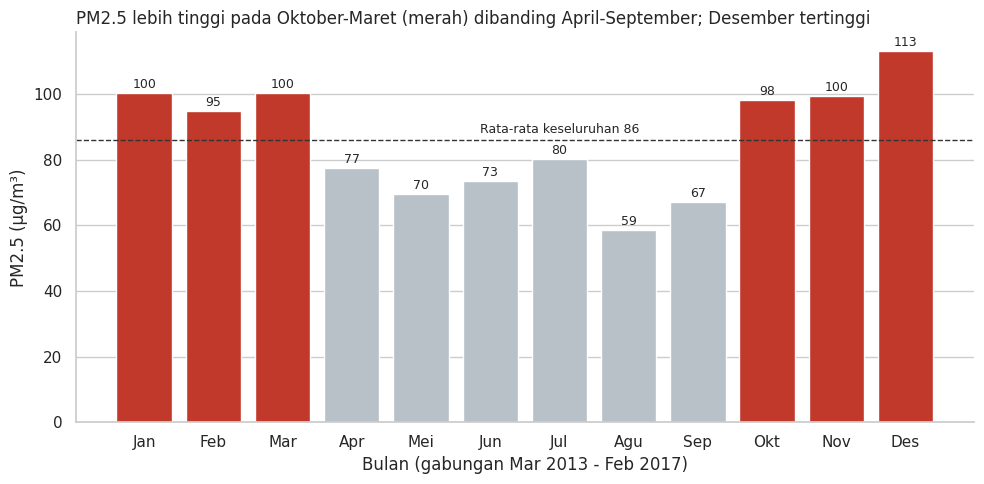

In [24]:
rata_all = dc["PM2.5"].mean()
m = dc.groupby("month")["PM2.5"].mean()
dingin = {10, 11, 12, 1, 2, 3}
fig, ax = plt.subplots(figsize=(10, 5))
warna = ["#C0392B" if i in dingin else "#B8C0C8" for i in m.index]
bars = ax.bar(nama_bulan, m.values, color=warna)
ax.axhline(rata_all, color="#333", ls="--", lw=1)
ax.text(6, rata_all + 2, f"Rata-rata keseluruhan {rata_all:.0f}", ha="center", fontsize=9)
for b, v in zip(bars, m.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.0f}", ha="center", fontsize=9)
ax.set_title("PM2.5 lebih tinggi pada Oktober-Maret (merah) dibanding April-September; Desember tertinggi", loc="left", fontsize=12)
ax.set_ylabel("PM2.5 (µg/m³)"); ax.set_xlabel("Bulan (gabungan Mar 2013 - Feb 2017)")
sns.despine(); plt.tight_layout(); plt.show()

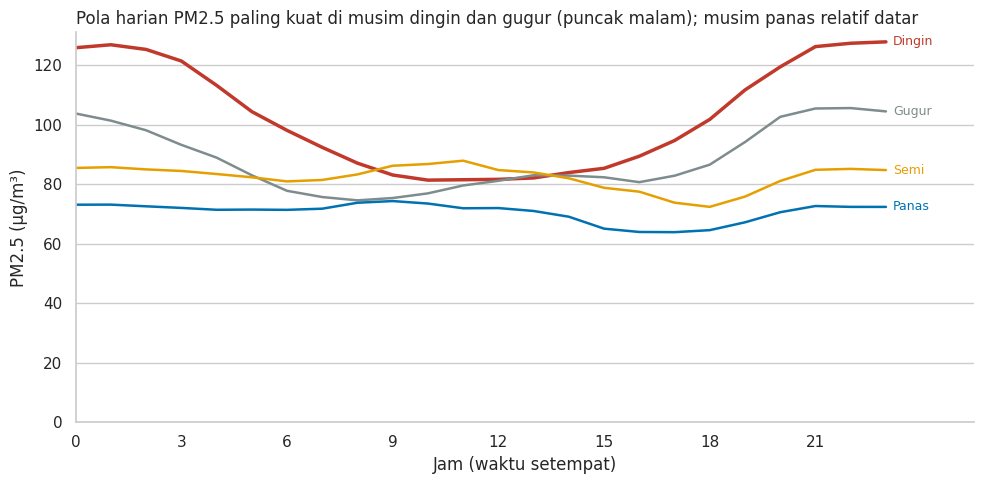

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))
pal = {"Dingin": "#C0392B", "Semi": "#E69F00", "Panas": "#0072B2", "Gugur": "#7F8C8D"}
for s in ["Dingin", "Gugur", "Semi", "Panas"]:
    d = dc[dc["musim"] == s].groupby("hour")["PM2.5"].mean()
    ax.plot(d.index, d.values, color=pal[s], lw=2.5 if s == "Dingin" else 1.8, label=s)
    ax.text(23.2, d.values[-1], s, color=pal[s], va="center", fontsize=9)
ax.set_xticks(range(0, 24, 3)); ax.set_xlim(0, 25.5)
ax.set_title("Pola harian PM2.5 paling kuat di musim dingin dan gugur (puncak malam); musim panas relatif datar", loc="left", fontsize=12)
ax.set_xlabel("Jam (waktu setempat)"); ax.set_ylabel("PM2.5 (µg/m³)"); ax.set_ylim(bottom=0)
sns.despine(); plt.tight_layout(); plt.show()

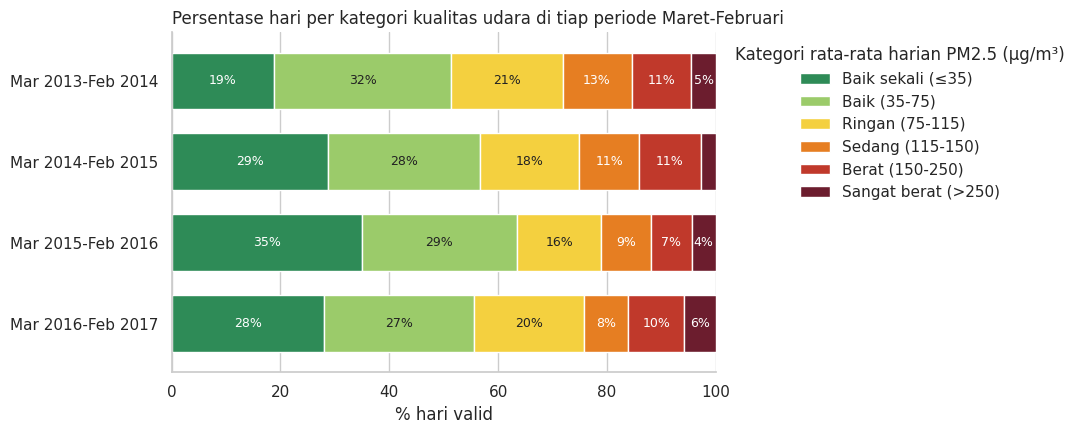

In [26]:
warna_kat = ["#2E8B57", "#9BCB6A", "#F4D03F", "#E67E22", "#C0392B", "#6C1D2E"]
ax = share.plot(kind="barh", stacked=True, color=warna_kat, figsize=(11, 4.5), width=0.7)
teks = ["white", "#222", "#222", "white", "white", "white"]
for cont, tc in zip(ax.containers, teks):
    ax.bar_label(cont, labels=[f"{v:.0f}%" if v >= 4 else "" for v in cont.datavalues],
                 label_type="center", fontsize=9, color=tc)
ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_title("Persentase hari per kategori kualitas udara di tiap periode Maret-Februari", loc="left", fontsize=12)
ax.set_xlabel("% hari valid"); ax.set_ylabel("")
ax.legend(title="Kategori rata-rata harian PM2.5 (µg/m³)", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
sns.despine(); plt.tight_layout(); plt.show()

**Insight:**


- **Bulan:** Desember adalah bulan dengan rata-rata tertinggi (113,1 µg/m³), diikuti Januari (100,3), Maret (100,2), November (99,5), dan Oktober (98,3). Agustus terendah (58,6). Pola yang **konsisten** adalah paruh **Oktober-Maret lebih tinggi daripada April-September di keempat periode** (mis. 109,4 vs 65,3 pada Mar 2016-Feb 2017).
- **Peringatan:** bulan *tertentu* yang paling buruk **tidak stabil** antar periode (Februari, Oktober, Desember, Desember). Desember tinggi karena dua dari empat tahun sangat parah (161,2 pada 2015 dan 149,7 pada 2016), sedangkan Desember 2014 hanya 55,1. Urutan Januari/Maret juga bertukar pada uji sensitivitas. Dengan demikian, kesimpulan yang dapat dipertahankan adalah pola *musim*, bukan *satu bulan tertentu*.
- **Rata-rata vs median:** median PM2.5 hampir sama di semua musim (58-64 µg/m³), tetapi rata-rata musim dingin 103,0 vs musim panas 70,7. Persentase jam dengan PM2.5 > 150 µg/m³ adalah 25,4% (dingin) vs 9,1% (panas). Artinya musim dingin tidak membuat kondisi "biasa" jauh lebih buruk. Yang berbeda adalah **frekuensi episode polusi berat**.
- **Jam:** rata-rata tertinggi pukul 22:00 (97,6) dan terendah pukul 16:00 (77,9), rasio hanya 1,25. Pola harian paling kuat di musim dingin (rasio 1,57; puncak pukul 23:00) dan paling datar di musim panas (rasio 1,16). Blok dini hari (92,8) dan malam (92,4) lebih tinggi daripada pagi (80,3) dan siang-sore (79,0).
- **Kategori harian** (1.420 hari valid, yaitu hari dengan minimal 20 jam data terukur): Baik sekali 27,7%, Baik 29,1%, Ringan 18,6%, Sedang 10,3%, Berat 10,0%, Sangat berat 4,4%. Persentase hari di atas 75 µg/m³ per periode: 48,7% → 43,4% → 36,6% → 44,4%. **Tidak ada tren menurun yang monoton**: periode 2015-16 terbaik, lalu memburuk lagi di 2016-17. Empat titik data tidak cukup untuk menyimpulkan tren jangka panjang.

### Pertanyaan 2: Selama periode Maret 2013 – Februari 2017, bagaimana perbedaan rata-rata PM2.5 menurut kecepatan angin dan arah angin, dan kombinasi mana yang menghasilkan PM2.5 tertinggi?

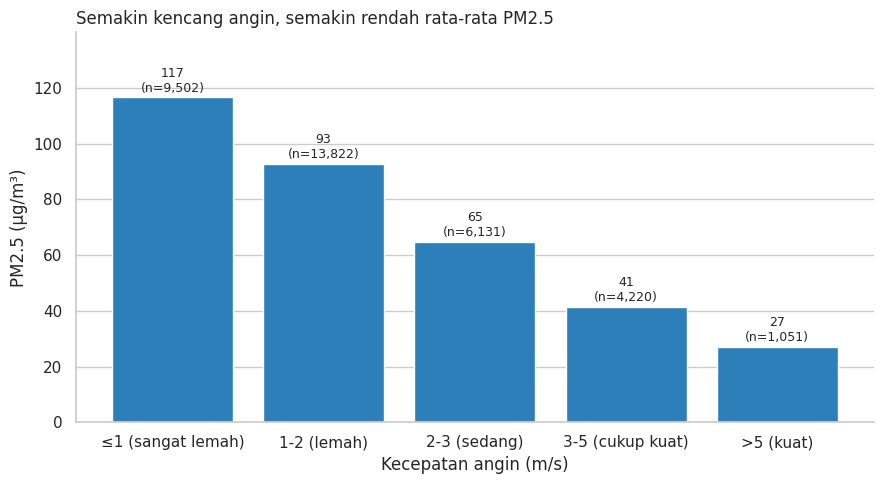

In [27]:
a = dc.groupby("kelas_angin", observed=True)["PM2.5"].agg(["mean", "count"])
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(a.index.astype(str), a["mean"], color="#2C7FB8")
for b, (mu, n) in zip(bars, a.values):
    ax.text(b.get_x() + b.get_width() / 2, mu + 2, f"{mu:.0f}\n(n={int(n):,})", ha="center", fontsize=9)
ax.set_title("Semakin kencang angin, semakin rendah rata-rata PM2.5", loc="left", fontsize=12)
ax.set_xlabel("Kecepatan angin (m/s)"); ax.set_ylabel("PM2.5 (µg/m³)"); ax.set_ylim(0, a["mean"].max() * 1.2)
sns.despine(); plt.tight_layout(); plt.show()

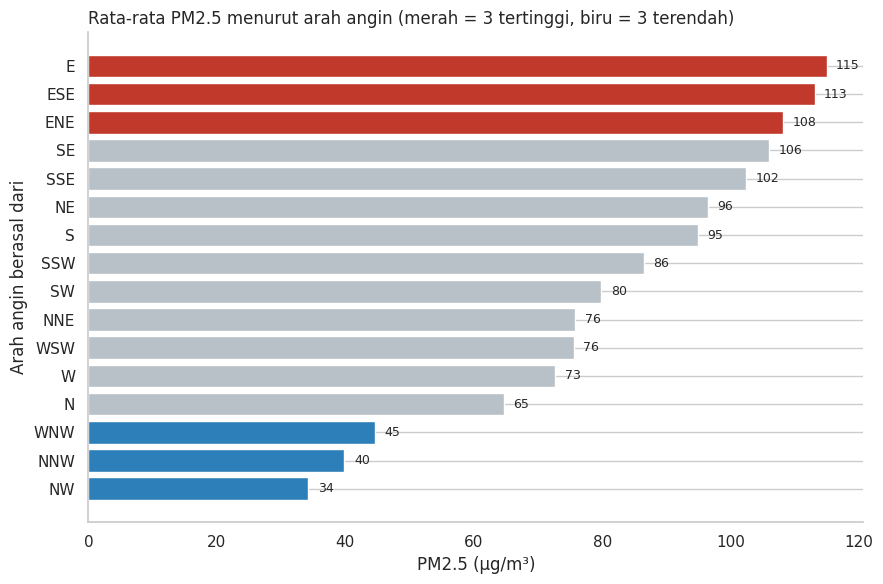

In [28]:
ar = dc.groupby("wd")["PM2.5"].mean().sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
warna = ["#C0392B" if i >= len(ar) - 3 else "#2C7FB8" if i < 3 else "#B8C0C8" for i in range(len(ar))]
ax.barh(ar.index, ar.values, color=warna)
for y, v in enumerate(ar.values):
    ax.text(v + 1.5, y, f"{v:.0f}", va="center", fontsize=9)
ax.set_title("Rata-rata PM2.5 menurut arah angin (merah = 3 tertinggi, biru = 3 terendah)", loc="left", fontsize=12)
ax.set_xlabel("PM2.5 (µg/m³)"); ax.set_ylabel("Arah angin berasal dari")
sns.despine(); plt.tight_layout(); plt.show()

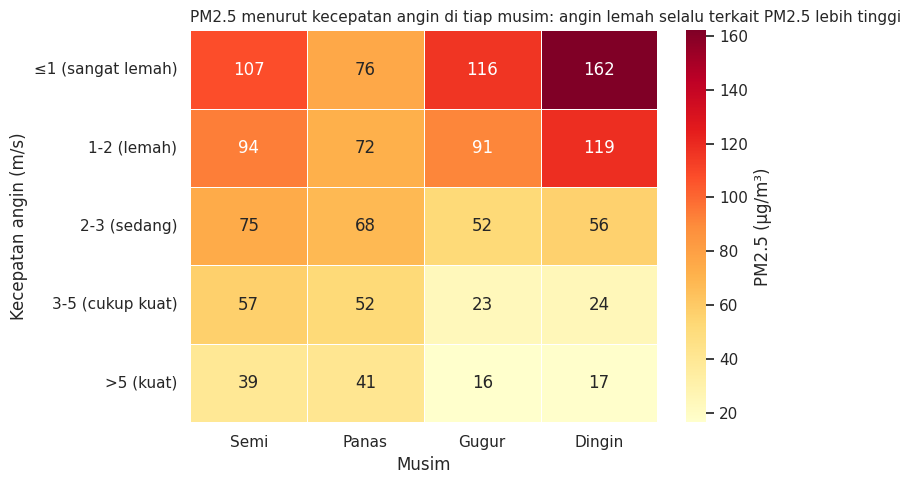

In [29]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(silang, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "PM2.5 (µg/m³)"}, linewidths=0.5, ax=ax)
ax.set_title("PM2.5 menurut kecepatan angin di tiap musim: angin lemah selalu terkait PM2.5 lebih tinggi", loc="left", fontsize=11)
ax.set_xlabel("Musim"); ax.set_ylabel("Kecepatan angin (m/s)")
plt.tight_layout(); plt.show()

**Insight:**


- **Kecepatan angin:** hubungan menurun jelas dan berurutan. Pada angin ≤1 m/s rata-rata PM2.5 adalah 116,6 µg/m³ (56,3% jam di atas 75), sedangkan pada angin >5 m/s hanya 27,0 (8,9% jam di atas 75). Korelasi negatif sedang (Pearson -0,30; Spearman -0,37), karena efeknya paling besar di rentang angin rendah (tidak linear).
- **Arah angin:** tertinggi saat angin berasal dari E (114,9), ESE (113,1), dan ENE (108,1). Terendah dari NW (34,2), NNW (39,9), dan WNW (44,7).
- **Faktor pengganggu:** arah dan kecepatan angin saling terkait. Angin NW rata-rata 3,34 m/s, sedangkan angin E hanya 1,30 m/s. Sebagian selisih antar-arah adalah efek kecepatan, sehingga arah tidak boleh dibaca terpisah (lihat Analisis Lanjutan).
- **Per musim:** angin lemah selalu berkaitan dengan PM2.5 lebih tinggi, tetapi besarnya berbeda. Dari ≤1 m/s ke >5 m/s, PM2.5 turun dari 162,1 ke 17,5 di musim dingin, namun hanya dari 75,8 ke 41,1 di musim panas. Sel terkecil (musim panas, >5 m/s) hanya n=49 jam.

## Analisis Lanjutan (Opsional)

### Manual Grouping dan Binning: Matriks Risiko Angin

Tujuan: menggabungkan kedua dimensi Q2 (kecepatan angin hasil *binning* dan kuadran arah hasil *manual grouping*) menjadi **matriks risiko**, yaitu persentase jam dengan PM2.5 > 75 µg/m³.

> Catatan: 75 µg/m³ adalah batas konsentrasi 24 jam Tingkat II pada GB 3095—2012 (Tabel 1). Pada analisis ini nilai tersebut diterapkan pada data per jam sebagai **indikator jam tinggi**, bukan penilaian kepatuhan terhadap standar.

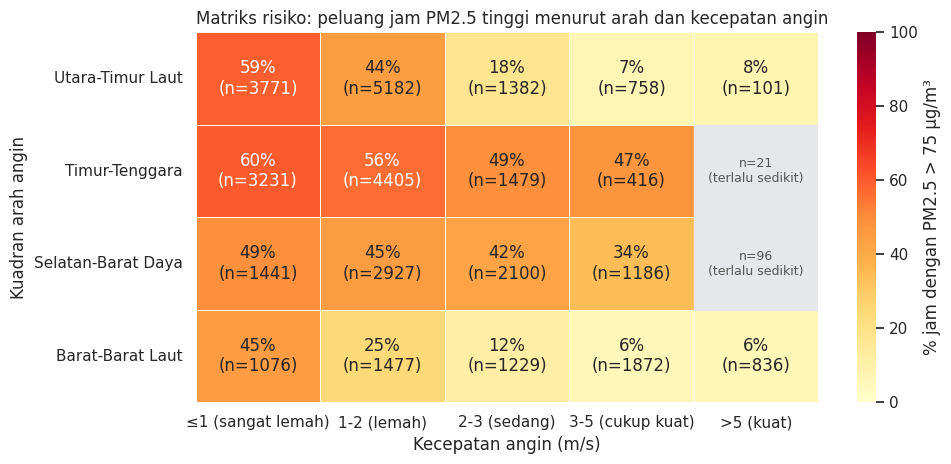

Sel dengan n < 100 perlu ditafsirkan hati-hati: 2


In [30]:
dk = dc.dropna(subset=["kuadran"]).copy()
dk["tinggi"] = dk["PM2.5"] > 75
risiko = dk.pivot_table(index="kuadran", columns="kelas_angin", values="tinggi", aggfunc="mean", observed=True) * 100
jumlah = dk.pivot_table(index="kuadran", columns="kelas_angin", values="tinggi", aggfunc="count", observed=True)
label = risiko.round(0).astype(int).astype(str) + "%\n(n=" + jumlah.astype(int).astype(str) + ")"

kecil = jumlah < 100
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.heatmap(risiko, annot=label, fmt="", cmap="YlOrRd", vmin=0, vmax=100, mask=kecil,
            cbar_kws={"label": "% jam dengan PM2.5 > 75 µg/m³"}, linewidths=0.5, linecolor="white", ax=ax)
for i in range(kecil.shape[0]):
    for j in range(kecil.shape[1]):
        if kecil.iloc[i, j]:
            ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=True, color="#E5E7EA", zorder=2))
            ax.text(j + 0.5, i + 0.5, f"n={jumlah.iloc[i, j]}\n(terlalu sedikit)", ha="center", va="center",
                    fontsize=9, color="#555", zorder=3)
ax.set_title("Matriks risiko: peluang jam PM2.5 tinggi menurut arah dan kecepatan angin", loc="left", fontsize=12)
ax.set_xlabel("Kecepatan angin (m/s)"); ax.set_ylabel("Kuadran arah angin")
plt.tight_layout(); plt.show()
print("Sel dengan n < 100 perlu ditafsirkan hati-hati:", int((jumlah < 100).sum().sum()))

**Insight:**


- Pada kecepatan angin 1-3 m/s, peluang jam dengan PM2.5 > 75 µg/m³ untuk kuadran **Timur-Tenggara** adalah 56% (1-2 m/s) dan 49% (2-3 m/s), jauh di atas kuadran **Barat-Barat Laut** (25% dan 12%). Pada 3-5 m/s selisihnya masih besar: 47% (Timur-Tenggara) vs 6% (Barat-Barat Laut). Dengan demikian, arah angin **tetap berpengaruh setelah kecepatan dikendalikan**, tidak hanya karena angin barat laut lebih kencang.
- Saat angin sangat lemah (≤1 m/s), semua kuadran berisiko tinggi (45%-60%), sehingga **angin lemah adalah faktor yang paling dominan**.
- Rata-rata PM2.5 menurut kuadran: Timur-Tenggara 110,8; Utara-Timur Laut 91,6; Selatan-Barat Daya 83,5; Barat-Barat Laut 43,7.
- Dua sel dengan n < 100 (mis. Timur-Tenggara pada >5 m/s, hanya 21 jam) **sengaja ditutup abu-abu** pada matriks dan tidak dijadikan dasar kesimpulan, karena persentasenya tidak stabil.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Selama Mar 2013-Feb 2017, PM2.5 di Dongsi secara konsisten lebih tinggi pada Oktober-Maret (rata-rata per periode 93,8-109,4 µg/m³) daripada April-September (62,7-81,3). Desember memiliki rata-rata bulanan tertinggi (113,1), tetapi bulan terburuk berganti antar periode. Perbedaan musim terutama berasal dari **episode berat yang lebih sering** di musim dingin (25,4% jam > 150 µg/m³ vs 9,1% di musim panas), bukan dari kondisi tipikal. Dalam sehari, PM2.5 tertinggi sekitar pukul 22:00 dan terendah sekitar pukul 16:00. Sebanyak 43,2% hari valid (614 dari 1.420) melampaui 75 µg/m³ dan tidak ada tren perbaikan monoton antar periode.
- **Conclusion pertanyaan 2:** PM2.5 turun tajam seiring naiknya kecepatan angin (116,6 pada ≤1 m/s vs 27,0 pada >5 m/s), dan angin dari sektor Timur-Tenggara berasosiasi dengan PM2.5 tertinggi. Efek arah bertahan setelah kecepatan dikendalikan (56% vs 25% jam tinggi pada 1-2 m/s). Kombinasi **angin lemah (≤2 m/s) dengan arah dari Timur-Tenggara** adalah yang paling berisiko (sekitar 56%-60% jam di atas 75 µg/m³).
- **Batasan analisis:**
  - **Cakupan data:** satu stasiun (Dongsi) dan empat tahun data. Hasil belum tentu berlaku untuk seluruh Beijing, dan empat periode tidak cukup untuk menyimpulkan tren jangka panjang.
  - **Asosiasi, bukan sebab-akibat:** sumber emisi, kelembapan, dan stabilitas atmosfer tidak dikendalikan. Hubungan angin dan PM2.5 merupakan pola statistik, bukan bukti mekanisme transportasi polusi.
  - **Kategori kualitas udara:** ditentukan hanya dari sub-indeks PM2.5 (IAQI) menurut HJ 633—2012, bukan AQI gabungan seluruh polutan, dan memakai versi standar 2012 (bukan revisi HJ 633—2026).
  - **Ambang 75 µg/m³ pada data per jam** merupakan indikator jam tinggi, bukan penilaian kepatuhan terhadap standar 24 jam.
  - **Kualitas data:** 6,1% baris memiliki PM2.5 > PM10 (dipertahankan dengan penanda; kesimpulan tidak berubah pada uji sensitivitas), 324 jam PM2.5 tetap kosong setelah interpolasi, serta CO dan NO2 tidak dianalisis karena celah data sangat panjang.
  - **Sel dengan sampel kecil** (n < 100) pada matriks risiko tidak dijadikan dasar kesimpulan.

**Rekomendasi Action Item:**
- **Peringatan dini berbasis prakiraan angin:** gunakan prakiraan cuaca untuk menyiagakan status polusi ketika kecepatan angin diperkirakan ≤2 m/s, terutama bila arah angin dari Timur-Tenggara. Kombinasi ini memberi peluang jam tinggi sekitar 56%-60% pada data historis.
- **Jadwalkan kesiapsiagaan musiman:** alokasikan pembatasan emisi dan kampanye kesehatan pada **Oktober-Maret** sebagai satu musim, bukan pada satu bulan tertentu karena bulan terburuk berubah tiap tahun.
- **Pesan paparan harian:** sarankan aktivitas luar ruang pada siang-sore (12:00-17:00) dan menghindari malam hingga dini hari, terutama pada musim dingin dan gugur, saat pola harian paling kuat. Ini temuan deskriptif, bukan rekomendasi medis.
- **Langkah analisis berikutnya:** validasi dengan stasiun lain dan variabel meteorologi tambahan sebelum dijadikan aturan operasional.